# Notes #

---

The density in the disk is prescribed by:
\begin{equation}
  \rho(r,\theta) = \rho_0 \left(\frac{r}{r_0}\right)^{-\alpha} \exp{\left(-\frac{\cos^2 \theta}{2\epsilon^2}\right)}
\end{equation}

The mass of the disk is then given by:
\begin{align}
  M_{\rm disc} & = \int_0^{2\pi}\!\int_{r_\min}^{r_\max}\!\int_{-z_\max}^{z_\max}\!\rho R\, dR\, dz\, d\phi ~ \mathrm{(ZRP)}= \int_0^{2\pi}\!\int_{r_\min}^{r_\max}\int_0^{\pi}\!\rho r^2 \sin \theta\, dr\, d\theta\, d\phi ~ \mathrm{(RTP)} \\
               & = 2\pi \rho_0 \int_{r_\min}^{r_\max}\! r^2 \left(\frac{r}{r_0}\right)^{-\alpha} dr \int_0^{\pi}\!\sin \theta \exp{\left(-\frac{\cos^2 \theta}{2\epsilon^2}\right)} d\theta \\
               & = 2\pi \rho_0 r_0^{\alpha} \frac{1}{(3-\alpha)} \left[r^{3-\alpha}\right]_{r_\min}^{r_\max} \left[-\sqrt{\frac{\pi}{2}} \epsilon ~ \mathrm{erf}\left(\frac{\cos\theta}{\sqrt{2}\epsilon}\right)\right]_0^{\pi} \\
               & =\left(2\pi\right)^{3/2} \rho_0 r_0^{\alpha} \epsilon \frac{1}{3-\alpha}\left(r_\max^{3-\alpha} - r_\min^{3-\alpha}\right) ~ \mathrm{erf}\left(\frac{1}{\sqrt{2}\epsilon} \right)\\
\end{align}

If one then sets the disc mass, $M_{\rm disc}$, the fiducial density factor, $\rho_0$, becomes known.

---

The Keplerian rotation period at cylindrical radius $R$ is given by:
\begin{equation}
  t_{\rm K} = \frac{2\pi}{\Omega_{\rm K}},
\end{equation}
where $\Omega_{\rm K} = \sqrt{GM_* / R^3}$.

For a central mass of $M_* = 1M_\odot$, and a radius of $R = 0.02$ au ($= r_\min$), one rotation is then $\simeq 8.926\times 10^4$ s.

---

The magnetic field is prescribed by the following magnetic flux function (Zanni et al. 2007):

\begin{equation}
  \Psi(r,\theta) = \frac{4}{3} r_0^2 B_{{\rm p},0} \left(\frac{r \sin \theta}{r_0}\right)^{3/4}\left[\frac{m^{5/4}}{(m^2 + \mathrm{cot}^2\theta)^{5/8}}\right],
\end{equation}
where $m$ is a parameter that controls the "bending" of the field, and $B_{{\rm p},0}$ is the initial poloidal magnetic field strength at $r_0$. I currently use a value of $m = 0.5$, following Suriano et al. (2017, 2018).

The magnetic field components are then given by:
\begin{align}
  B_r(r,\theta) & = \phantom{-}\frac{1}{r^2 \sin \theta}\frac{\partial \Psi}{\partial \theta};\\
  B_\theta(r,\theta) & = -\frac{1}{r \sin \theta}\phantom{^2}\frac{\partial \Psi}{\partial r}.
\end{align}

Which thus gives magnetic field components:

In [4]:
%matplotlib notebook
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import cm
import dispatch
import dispatch.select
import itertools
import sys
import astropy.constants as cnst
from dispatch.graphics import curvilinear_transforms
from read_pebbles_dict import read_pebbles_dict

au = cnst.au.cgs.value

In [5]:
def patch_grid_edges(p, slicedir, scale_factor=1.0, truecoords=True):
    """
    Using the corners of the patch, create a matplotlib patch that draws
    the grid edges.

    """

    from matplotlib.patches import Rectangle, Wedge

    lo_corners = []
    hi_corners = []
    origin = p.llc_cart
    for o,s in zip(origin,p.size):
        lo_corners.append(o)
        hi_corners.append(o + s)
    active_corners = lo_corners, hi_corners

    if truecoords:
        if slicedir == 1:
            llx, urx = active_corners[0][1], active_corners[1][1]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 2:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 3:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][1], active_corners[1][1]
    else:
        if slicedir == 1:
            llx, urx = p.llc_cart[1], p.llc_cart[1] + p.size[1]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 2:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 3:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[1], p.llc_cart[1] + p.size[1]

    if p.mesh_type == 'Cartesian' or truecoords: # Cartesian or Cartesian-like
        llx *= scale_factor
        urx *= scale_factor
        if p.mesh_type == 'Cartesian':
            lly *= scale_factor
            ury *= scale_factor
        edges = Rectangle((llx,lly),width=(urx-llx),height=(ury-lly),fc='none',lw=1.0,
                          ec='0.7',linestyle='dashed',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'spherical':
        # note that matplotlib sets theta=0 to what we typically consider to be theta=pi/2.
        thetamin = round(active_corners[0][1]*180.0/np.pi-90.0,3)
        thetamax = round(active_corners[1][1]*180.0/np.pi-90.0,3)
        llx, urx = active_corners[0][0], active_corners[1][0]
        if slicedir == 3 or slicedir == 2:
            llx *= scale_factor
            urx *= scale_factor
        edges = Wedge((0.0,0.0),urx,thetamin,thetamax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'cylindrical':
        llx *= scale_factor
        urx *= scale_factor
        if slicedir == 3:
            lly *= scale_factor
            ury *= scale_factor
        # note that matplotlib sets theta=0 to what we typically consider to be theta=pi/2.
        phimin = round(active_corners[0][2]*180.0/np.pi-90.0,3)
        phimax = round(active_corners[1][2]*180.0/np.pi-90.0,3)
        llx, urx = active_corners[0][1], active_corners[1][1]
        edges = Wedge((p.position[0]*scale_factor,p.position[1]*scale_factor),urx,phimin,phimax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)

    return edges

In [6]:
iout = 300
snap = dispatch.snapshot(iout=iout,data='../data')
print "No. patches:",len(snap.patches)
print "Domain size:",snap.patches[0].box
print "Patch size:",snap.patches[0].size
print "I/O format:", snap.patches[0].ioformat
print "Time:", snap.patches[0].time, snap.patches[0].time/8.925e4
print "Mesh type:", snap.patches[0].mesh_type
time = snap.patches[0].time
#print "ID, time, nsteps, ntotcells, nghost, position, mesh type"
#for p in snap.patches:
#    print "{:03d}".format(p.id),p.time,p.istep,p.gn,p.ng,p.position,p.mesh_type

No. patches: 126
Domain size: [1.48745980e+14 3.13064743e+00 1.00000000e+00]
Patch size: [8.26366556e+12 4.47235347e-01 6.28318531e+00]
I/O format: 6
Time: 133875.0 1.5
Mesh type: spherical


In [4]:
print snap.patches[0].idx.vars

{0: 'd', 1: 'e', 2: 'et', 3: 'px', 4: 'py', 5: 'pz', 6: 'bx', 7: 'by', 8: 'bz', 9: 'phi'}


<IPython.core.display.Javascript object>


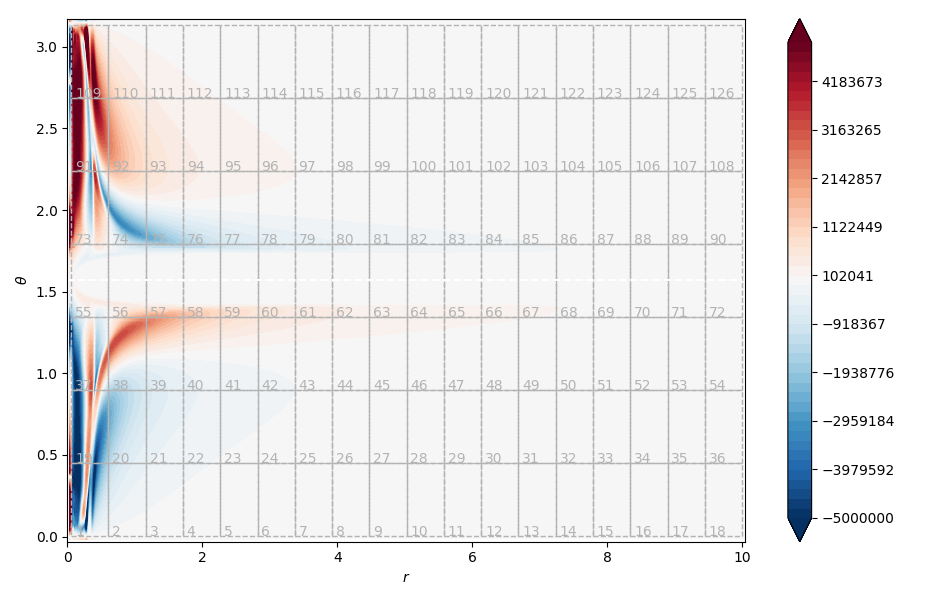

1 2 3 4 5 6 7 8 9 10

/home/jramsey/repos/dispatch2-clean/utilities/python/dispatch/_dispatch.py:196: RuntimeWarning: invalid value encountered in divide
  return mem('p2')/ydown('d')/patch.geometric_factors['h2c'][:,np.newaxis,np.newaxis]


 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
min., max.: -12892497.067941172 12897471.68838738


In [7]:
varidx = 'u2'
truecoords = True
fig1 = plt.figure(figsize=(9.3,6.0))
fig1.clf()
cax = fig1.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01*np.pi,ymax=1.01*np.pi)
gqmin, gqmax = 1.0e99, -1.0e99
pvarlog = False
if varidx == 'd' : pvmin, pvmax, pvarlog = -14.0, -10.0, True # d
if varidx == 'u2': pvmin, pvmax = -5.0e6, 5.0e6 # v2
if varidx == 'u1': pvmin, pvmax = -3.0e5, 1.0e7 # v1
if varidx == 'e' : pvmin, pvmax, pvarlog = -1.0, 6.5, True # e
if varidx == 'u3': pvmin, pvmax, pvarlog = -3.0, 8.0, True # v3
if varidx == 'b2': pvmin, pvmax = -5.0e1, 2.0 # b2
if varidx == 'b1': pvmin, pvmax = -5.0e3, 5.0e3 # b1
if varidx == 'b3': pvmin, pvmax = -1.0e2, 1.0e2 # b3
#pvmin, pvmax = -5.0, 5.0 # b3
levels = np.linspace(pvmin,pvmax,50)
for p in snap.patches:
    print p.id,
    var = p.var(varidx)
    if pvarlog: var = np.log10(var)
    gqmin = min(gqmin, np.nanmin(var))
    gqmax = max(gqmax, np.nanmax(var))
    plt.contourf(p.x/au,p.y,var.squeeze().T,levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    edges = patch_grid_edges(p,3,truecoords=truecoords,scale_factor=1.0/au)
    cax.add_patch(edges)
    offset = [3*x for x in p.ng]
    offset[0] = 0
    gn_xpos = p.x[offset[1]]/au
    gn_ypos = p.y[offset[2]]
    cax.annotate(str(p.id),(gn_xpos,gn_ypos),color='0.7',fontsize=10,zorder=1.0,va='bottom')

cax.plot([0.0,10.0],[np.pi*0.5,np.pi*0.5],'w--')
cax.set_xlabel(r"$r$")
cax.set_ylabel(r"$\theta$")
plt.colorbar()
fig1.tight_layout()
print
print "min., max.:",gqmin,gqmax

In [7]:
pp = snap.patches[55-1]
print pp.id
print snap.ntotal
print pp.kind

55
126
zeus_mhd_patch


In [47]:
def average_down(q, axis=0):
    n = 2 # 2-point average (equivalent to i-1 and i)
    x = np.cumsum(q,axis=axis,dtype=np.float)
    if axis == 0 and q.shape[0] > 1:
        x[n:,:,:] = x[n:,:,:] - x[:-n,:,:]
        x[n - 1:,:,:] = x[n - 1:,:,:] / n
        x[-1,:,:] = q[-2,:,:] # first and last element of average are copied from original
    elif axis == 1 and q.shape[1] > 1:
        x[:,n:,:] = x[:,n:,:] - x[:,:-n,:]
        x[:,n - 1:,:] = x[:,n - 1:,:] / n
        x[:,-1,:] = q[:,-2,:]
    elif axis == 2 and q.shape[2] > 1:
        x[:,:,n:] = x[:,:,n:] - x[:,:,:-n]
        x[:,:,n - 1:] = x[:,:,n - 1:] / n
        x[:,:,-1] = q[:,:,-2]
    else:
        x = q.copy()
    return x

pp = snap.patches[55-1]
print pp.id
d = pp.var('d')
print d.shape
dxdn = average_down(d,axis=0)
dydn = average_down(d,axis=1)
print d[10,:,0]
dh = np.zeros(d[10,:,0].shape)
for i in xrange(dh.shape[0]-1):
    dh[i+1] = (d[10,i,0] + d[10,i+1,0])/2
for i in xrange(dh.shape[0]):
    print i,d[10,i,0],dydn[10,i,0],dh[i]

55
(45, 47, 1)
[3.9004829e-13 3.9004829e-13 3.9004829e-13 3.9004829e-13 3.9004829e-13
 3.9004829e-13 3.9004829e-13 3.9004829e-13 3.9004829e-13 6.8561164e-11
 1.2625070e-10 2.2206695e-10 3.7300252e-10 5.9815003e-10 9.1554869e-10
 1.3373271e-09 1.8638051e-09 2.4780005e-09 3.1425440e-09 3.8009431e-09
 4.3842174e-09 4.8222977e-09 5.0577511e-09 5.0581597e-09 4.8234665e-09
 4.3859885e-09 3.8030916e-09 3.1448266e-09 2.4801989e-09 1.8657578e-09
 1.3389420e-09 9.1680014e-10 5.9906258e-10 3.7363054e-10 2.2247576e-10
 1.2650288e-10 6.8708761e-11 3.9004829e-13 3.9004829e-13 3.9004829e-13
 3.9004829e-13 3.9004829e-13 3.9004829e-13 3.9004829e-13 3.9004829e-13
 3.9004829e-13 0.0000000e+00]
0 3.900483e-13 3.9004829097480376e-13 0.0
1 3.900483e-13 3.9004829097480376e-13 3.9004829097480376e-13
2 3.900483e-13 3.9004829097480376e-13 3.9004829097480376e-13
3 3.900483e-13 3.9004829097480376e-13 3.9004829097480376e-13
4 3.900483e-13 3.9004829097480376e-13 3.9004829097480376e-13
5 3.900483e-13 3.9004829097480

In [101]:
pp = snap.patches[49-1]
#pp = snap.patches[3]
print pp.id
d = pp.var('d')
print 'd:',np.nanmin(d),np.nanmax(d),d.shape
print 'd(*,2):',d[:,2,0]
print 'd(*,3):',d[:,3,0]
print 'd(*,4):',d[:,4,0]
print 'd(*,5):',d[:,5,0]
b2 = pp.var('b2')
print 'b2:',b2[:,10,0]
print 'b2:',b2[10,:,0]
v1 = pp.var('u1')
print 'v1:',v1[:,10,0]
b1 = pp.var('b1')
print 'b1(*,22):',b1[:,22,0]
print 'b1(0,*):',b1[0,:,0]
e1 = pp.var('e')
print 'e1(*,10):',e1[:,10,0]
print 'e1(*,2):',e1[:,2,0]
print 'e1(3,*):',e1[2,:,0]
b3 = pp.var('b3')
print 'b3(0,*):',b3[0,:,0]

49
d: 0.0 5.5787983e-12 (41, 47, 1)
d(*,2): [2.6972543e-14 2.6972543e-14 2.6972543e-14 3.7571122e-14 5.0256887e-14
 7.1181674e-14 1.0773258e-13 1.6712123e-13 2.3593210e-13 2.8119919e-13
 2.9040477e-13 2.8083192e-13 2.5179533e-13 2.2257347e-13 2.0418926e-13
 1.8454224e-13 1.4708560e-13 1.0967459e-13 9.5199259e-14 9.0129815e-14
 8.5608441e-14 8.0630713e-14 7.5638450e-14 7.0778954e-14 6.6217512e-14
 6.2022361e-14 5.8221711e-14 5.4788690e-14 5.1680929e-14 4.8862610e-14
 4.6299353e-14 4.3960390e-14 4.1819057e-14 3.9852406e-14 3.8040694e-14
 3.6366899e-14 3.4815616e-14 3.3376744e-14 3.2035796e-14 3.0785578e-14
 0.0000000e+00]
d(*,3): [2.3615038e-14 2.3615038e-14 2.3615038e-14 3.6435380e-14 4.8997197e-14
 6.8760481e-14 1.0484514e-13 1.6471706e-13 2.3534774e-13 2.8343831e-13
 2.9425746e-13 2.8550957e-13 2.5665239e-13 2.2654613e-13 2.0781574e-13
 1.8705775e-13 1.4743943e-13 1.1027145e-13 9.6654374e-14 9.1586034e-14
 8.6729743e-14 8.1455377e-14 7.6150647e-14 7.1122870e-14 6.6431690e-14
 6.215872

In [50]:
pp = snap.patches[49-1]
b1_0 = pp.var('b1')
b1_0[:,10,0]

memmap([-7.02986572e+03, -2.33910904e+02, -9.86083450e+01,
        -5.76799774e+01, -3.91546745e+01, -2.95150642e+01,
        -2.35232620e+01, -1.94288883e+01, -1.64656239e+01,
        -1.42298660e+01, -1.24882145e+01, -1.10966730e+01,
        -9.96173573e+00, -9.02014065e+00, -8.22760677e+00,
        -7.55225945e+00, -6.97059631e+00, -6.46492386e+00,
        -6.02168322e+00, -5.63031340e+00, -5.28247833e+00,
        -4.97150946e+00, -4.69201517e+00, -4.43959236e+00,
        -4.21060753e+00, -4.00204134e+00, -3.81136489e+00,
        -3.63644171e+00, -3.47545886e+00, -3.32686567e+00,
        -3.18933082e+00, -3.06170344e+00, -2.94298434e+00,
        -2.83230233e+00, -2.72889447e+00, -2.63209009e+00,
        -2.54129672e+00, -2.45598912e+00, -2.37569880e+00,
        -2.30001569e+00, -2.22856450e+00], dtype=float32)

56


<IPython.core.display.Javascript object>


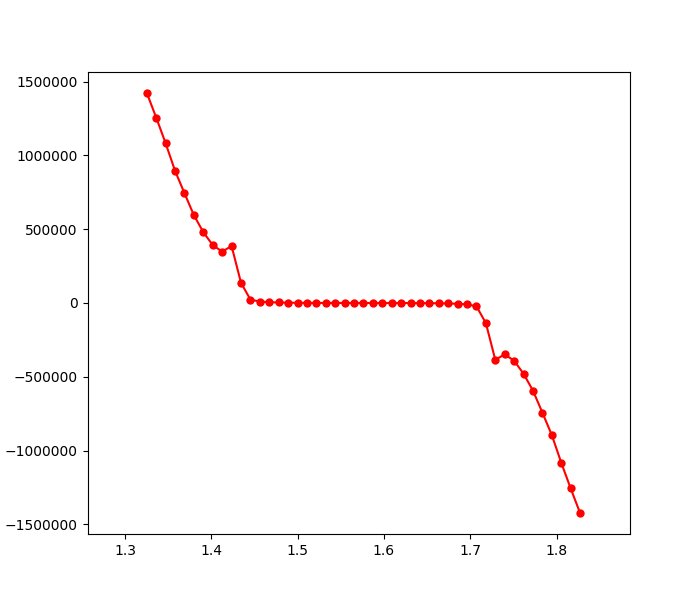

(1.2566370614359172,
 1.8849555921538759,
 -1565948.8617821615,
 1565651.1312175398)

In [9]:
pp = snap.patches[56-1]
print pp.id
var = pp.var('u2')
fig1d = plt.figure(figsize=(7.0,6.0))
fig1d.clf()
cax = fig1d.add_subplot(1,1,1)
cax.plot(pp.y,var[20,:,0],'ro-',mew=0.0)
cax.axis(xmin=0.4*np.pi,xmax=0.6*np.pi)
#cax.plot(pp.x/au,b1_0[:,10,0],'bo-',mew=0.0)
#cax.axis(xmax=0.5*np.pi-0.5,xmin=0.5*np.pi+0.5)
#cax.xaxis.set_minor_locator(AutoMinorLocator(10))

In [25]:
for p in snap.patches:
    print "ID:",p.id,"; dt=",p.dtime,'; t=',p.time,'(',p.time/8.925e4,') ; nsteps=',p.istep

ID: 1 ; dt= 0.0785593132658 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 2 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 3 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 4 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 5 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 6 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 7 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 8 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 9 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 10 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 11 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 12 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 13 ; dt= 1.31002235237 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 14 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 15 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID: 16 ; dt= 223.125 ; t= 163773.75 ( 1.835 ) ; nsteps= 27384
ID:

<IPython.core.display.Javascript object>


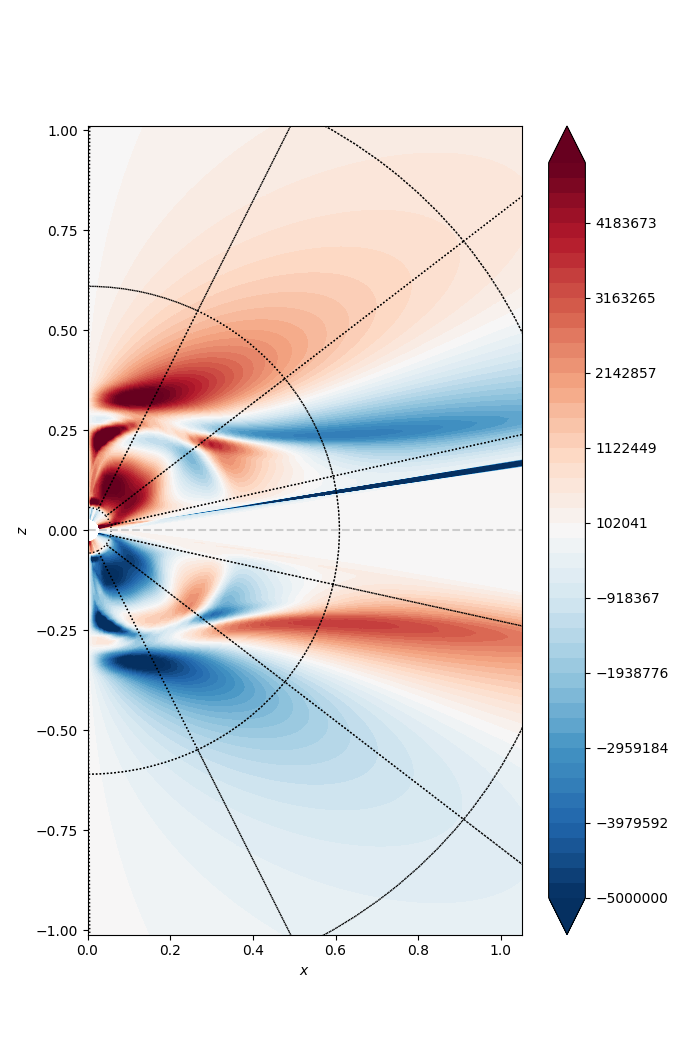

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
min., max.: -inf inf


In [21]:
varidx = 'u2'
truecoords = False
pvarlog = False
pabsval = False
fig2 = plt.figure(figsize=(7.0,10.5))
fig2.clf()
cax = fig2.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=1.05,ymin=-1.01,ymax=1.01)
gqmin, gqmax = 1.0e99, -1.0e99
if varidx == 'd' : pvmin, pvmax, pvarlog = -16.0, -8.0, True # d
if varidx == 'u2': pvmin, pvmax = -5.0e6, 5.0e6 # v2
if varidx == 'u1': pvmin, pvmax = -5.0e5, 5.0e7 # v1
if varidx == 'e' : pvmin, pvmax, pvarlog = -1.0, 6.5, True # e
if varidx == 'u3': pvmin, pvmax, pvarlog = -3.0, 8.0, True # v3
if varidx == 'b2': pvmin, pvmax = -1.0e2, 5.0 # b2
if varidx == 'b1': pvmin, pvmax = -1.0e4, 1.0e4 # b1
if varidx == 'b3': pvmin, pvmax = -5.0e0, 5.0e0 # b3
levels = np.linspace(pvmin,pvmax,50)
for p in snap.patches:
    print p.id,
    var = p.var(varidx)
    if pabsval: var = np.abs(var)
    if pvarlog: var = np.log10(var)
    gqmin = min(gqmin, np.nanmin(var))
    gqmax = max(gqmax, np.nanmax(var))
    # convert coords. from RTP to XYZ for pretty plotting
    x, y, z = curvilinear_transforms.rtp_to_xyz(p.x,p.y,p.z,phi_rotate=np.pi)
    conf = plt.contourf(x.squeeze()/au,z.squeeze()/au,var.squeeze(),levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    #plt.contour(x.squeeze()/au,z.squeeze()/au,var.squeeze(),[-10.0],colors='w',lw=0.5)
    edges = patch_grid_edges(p,3,truecoords=truecoords,scale_factor=1.0/au)
    cax.add_patch(edges)
    #offset = [3*x for x in p.ng]
    #offset[0] = 0
    #gn_xpos = p.x[offset[1]]/au
    #gn_ypos = p.y[offset[2]]
    #cax.annotate(str(p.id),(gn_xpos,gn_ypos),color='0.7',fontsize=13,zorder=1.0,va='bottom')

cax.plot([0.0,10.0],[0.0,0.0],color='0.8',linestyle='dashed')
cax.set_xlabel(r"$x$")
cax.set_ylabel(r"$z$")
plt.colorbar(conf)
print
print "min., max.:",gqmin,gqmax

In [30]:
pebbles = None
for p in snap.patches:
    print p.id,
    pebbles = read_pebbles_dict(pebbles=pebbles,ip=p.id,it=iout,data='../data')

print
print "no. pebbles:",len(pebbles)
x, y = [], []
sizes = []
s_min, s_max = 1.0e99, -1.0e99
v3_min, v3_max = 1.0e99, -1.0e99
for peb in pebbles.itervalues():
    xx, yy, dummy = peb.p[0]
    x.append(xx)
    y.append(yy)
    ss = peb.s
    sizes.append(ss)
    s_min, s_max = min(s_min, peb.s), max(s_max, peb.s)
    v3_min, v3_max = min(v3_min, peb.v[0][2]), max(v3_max, peb.v[0][2])
    if peb.v[0][2] > 1.0e8: print peb.id, peb.owner

x = np.array(x)
y = np.array(y)
sizes = np.array(sizes)
print "Size min., max.:", s_min, s_max
print "velocity min., max.:", v3_min, v3_max
print "x min., max.:", x.min(), x.max()

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60
no. pebbles: 85918
Size min., max.: 0.0010013162 0.9994055
velocity min., max.: -8.69961e-14 35343308.0
x min., max.: 928778750000.0 149582600000000.0


<IPython.core.display.Javascript object>


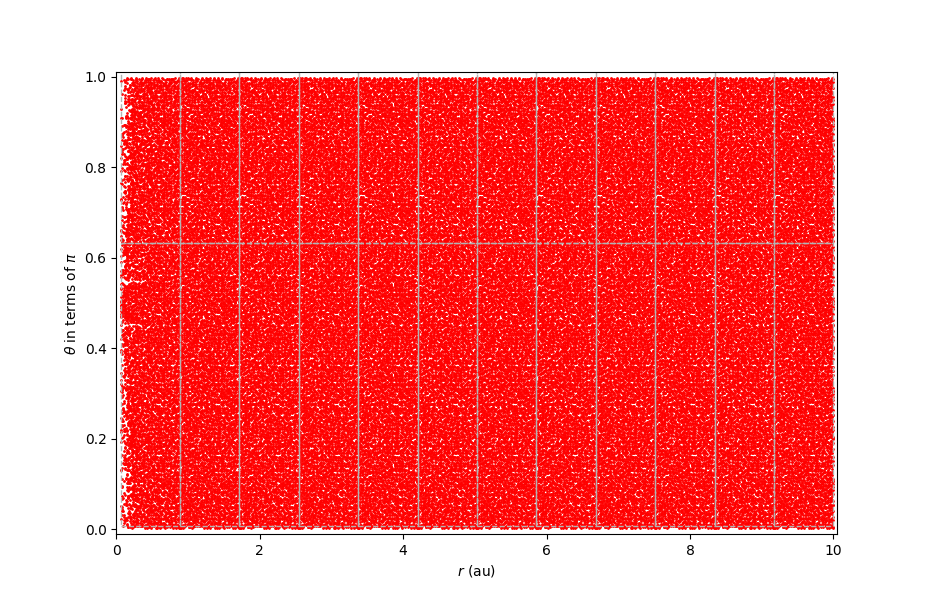

Text(0.5,0,'$r$ (au)')

In [31]:
fig3 = plt.figure(figsize=(9.3,6.0))
fig3.clf()
cax = fig3.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01,ymax=1.01)
cax.scatter(x/au,y/np.pi,s=1.0,c='r',marker='o',zorder=-1.0)
for p in snap.patches:
    edges = patch_grid_edges(p,3,truecoords=True,scale_factor=1.0/au)
    cax.add_patch(edges)

cax.set_ylabel(r"$\theta$ in terms of $\pi$")
cax.set_xlabel(r"$r$ (au)")

In [33]:
pp = snap.patches[22-1]
print "ID:",pp.id
pebs = read_pebbles_dict(pebbles=None,ip=pp.id,it=iout,data='../data')
print "no. pebbles:",len(pebs)
x, y = [], []
for peb in pebs.itervalues():
    xx, yy, dummy = peb.p[0]
    x.append(xx)
    y.append(yy)

x = np.array(x)
y = np.array(y)

print pebs[28654].v
print pebs[28654].t
print pebs[29031].v
print pebs[29031].t

ID: 22
no. pebbles: 1437


KeyError: 28654

56623


Text(0,0.5,'$N$')

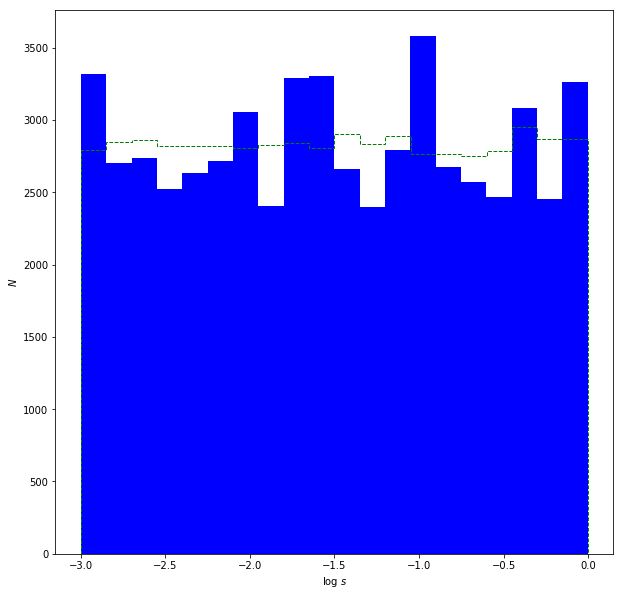

In [38]:
fig4 = plt.figure(figsize=(8.,8.))
fig4.clf()
cax = fig4.add_subplot(1,1,1)
print len(sizes)
n, bins, hist = cax.hist(np.log10(sizes),20,facecolor='blue',log=False)
log_size_rand = -3.0 * np.random.rand(len(sizes))
n, bins, hist = cax.hist(log_size_rand,20,histtype='step',color='g',linestyle='dashed')
cax.set_xlabel(r"log $s$")
cax.set_ylabel(r"$N$")

In [34]:
import trace_utils as tu
reload(tu)

<module 'trace_utils' from 'trace_utils.pyc'>

In [35]:
tr = tu.traces(verbose=1,cache=True)

837 trace file names in self.files


In [36]:
disk_pebs = []
t_max = 0.0
for peb in tr.traces:
    if peb.p[1,0] > 1.4 and peb.p[1,0] < 1.7:
        disk_pebs.append(peb)
        t_max = max(t_max,peb.t.max())

print "No. of pebbles 'in the disk':",len(disk_pebs)
print "time max.:",t_max

No. of pebbles 'in the disk': 83
time max.: 164315.53


<IPython.core.display.Javascript object>


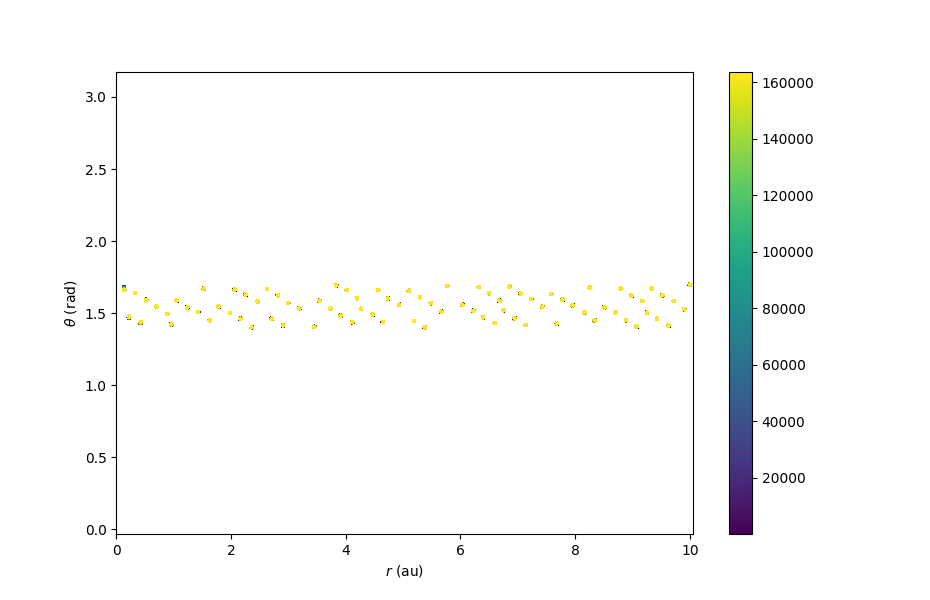

36700 36800 36900 37000 37100 37200 37300 38200 38300 38400 38500 38600 38800 39700 39800 39900 40000 40100 40200 40300 41200 41300 41500 41600 41700 41800 42700 42800 42900 43000 43100 43200 43300 43400 44300 44400 44500 44600 44700 44800 45700 45800 46000 46100 46200 46300 46400 47300 47400 47500 47600 47700 47800 47900 48800 48900 49000 49100 49200 49300 49400 53300 53400 53500 53600 53700 53800 53900 54000 51800 51900 52000 52100 52200 52300 52400 50300 50400 50500 50600 50700 50800 50900
164315.53


In [37]:
fig5 = plt.figure(figsize=(9.3,6.0))
fig5.clf()
cax = fig5.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01*np.pi,ymax=1.01*np.pi)
t_max = 0.0
for peb in disk_pebs:
    print peb.id,
    t_max = max(t_max, peb.t.max())
    plt.plot(peb.p[0]/au,peb.p[1],marker='o',ms=1.0,linestyle='-',color='k',zorder=0.0)
    sc = cax.scatter(peb.p[0]/au,peb.p[1],s=3.0,c=peb.t,zorder=1.0)

cax.set_ylabel(r"$\theta$ (rad)")
cax.set_xlabel(r"$r$ (au)")
plt.colorbar(sc)
print
print t_max

In [29]:
pp0 = disk_pebs[0]
print pp0.id
print pp0.n
print "P(0):",pp0.p[0]/au
print "P(1):",pp0.p[1]
print "V(0):",pp0.v[0]
print "V(1):",pp0.v[1]
print "V(2):",pp0.v[2]
print "AG(0):",pp0.ag[0]
print "AG(1):",pp0.ag[1]
print "AD(0):",pp0.ad[0]
print "AD(1):",pp0.ad[1]
print "AD(2):",pp0.ad[2]
print "t:",pp0.t

27300
2976
P(0): [0.10222118 0.10222118 0.10222118 ... 0.67926395 0.6794847  0.6795815 ]
P(1): [1.4540048 1.4540048 1.4540048 ... 1.391555  1.3915564 1.391557 ]
V(0): [-4.2666140e+00 -1.4935116e+01 -4.1826149e+01 ...  1.8505936e+07
  1.8502988e+07  1.8501698e+07]
V(1): [1.1909040e-09 1.2607364e-08 9.4950224e-08 ... 8.4639523e+04 8.4794992e+04
 8.4863336e+04]
V(2): [      0.        0.        0.  ... 1057005.2 1056475.1 1056242.9]
AG(0): [-56.768562  -56.768562  -56.768562  ...  -1.1749122  -1.1742203
  -1.1739475]
AG(1): [0.         0.         0.         ... 0.03987898 0.0398257  0.03978184]
AD(0): [ 6.9445385e-05  3.1326199e-04  9.2641392e-04 ... -1.5381364e+01
 -1.5344635e+01 -1.5318522e+01]
AD(1): [2.1127098e-08 7.3955412e-08 2.0711970e-07 ... 8.3852684e-01 8.4298354e-01
 8.4432811e-01]
AD(2): [ 0.         0.         0.        ... -2.9743235 -2.9722981 -2.9695952]
t: [7.5158186e-02 2.6308927e-01 7.3679465e-01 ... 4.1808350e+05 4.1826200e+05
 4.1834025e+05]


<IPython.core.display.Javascript object>


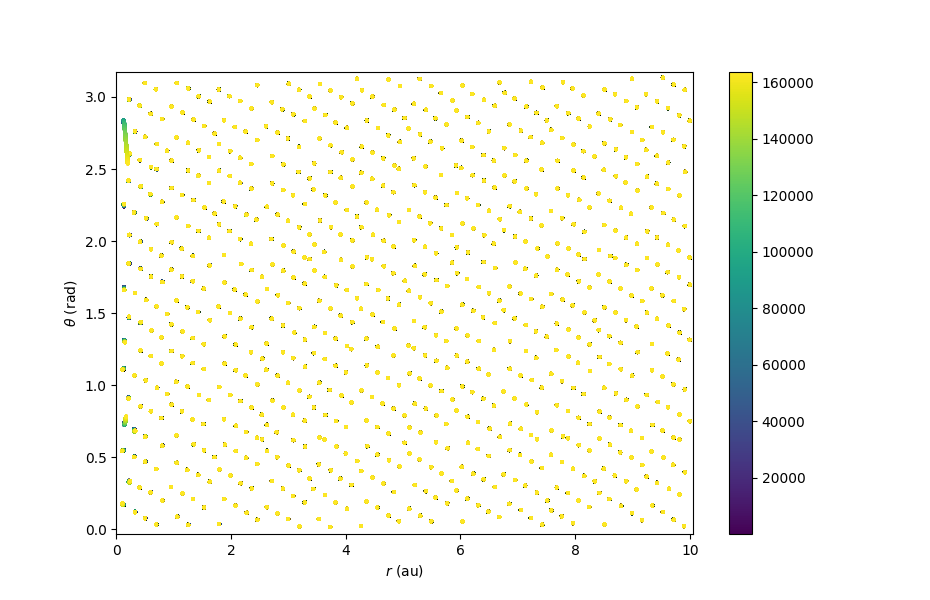

In [38]:
fig6 = plt.figure(figsize=(9.3,6.0))
fig6.clf()
cax = fig6.add_subplot(1,1,1)
cax.axis(xmin=0.0,xmax=10.05,ymin=-0.01*np.pi,ymax=1.01*np.pi)
for peb in tr.traces:
    plt.plot(peb.p[0]/au,peb.p[1],marker='o',ms=1.0,linestyle='-',color='k',zorder=0.0)
    sc = cax.scatter(peb.p[0]/au,peb.p[1],s=3.0,c=peb.t,zorder=1.0)

cax.set_ylabel(r"$\theta$ (rad)")
cax.set_xlabel(r"$r$ (au)")
plt.colorbar(sc)

In [125]:
theta = np.linspace(0.0,np.pi,720) # rad
r = np.logspace(-5.0,2.0,200) # AU
rr, tt = np.meshgrid(r, theta, indexing='ij')
r0 = 0.02 # AU
m = [0.1,0.3,0.5,0.9,1.0,10.0]
Bp0 = 220.7
psis = []
brs = []
for mm in m:
    psi = (4.0/3.0) * r0**2 * Bp0 * (rr * np.sin(tt) / r0)**(0.75) * mm**(1.25) / (mm**2 + np.tan(tt)**(-2.0))**(0.625)
    psis.append(psi)
    br = (4.0/3.0) * Bp0 * (r0 / rr)**1.25 / (np.sin(tt))**0.25 * mm**1.25 / (mm**2 + np.tan(tt)**(-2.0))**(0.625) * (0.75 / np.tan(tt) + 1.25 / (np.tan(tt) * np.sin(tt)**2) / (mm**2 + np.tan(tt)**(-2.0)))
    brs.append(br)
    print mm, psi.min(), psi.max(), np.nanmin(br), np.nanmax(br)

/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:10: RuntimeWarning: divide by zero encountered in power
  # Remove the CWD from sys.path while we load stuff.
/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:12: RuntimeWarning: divide by zero encountered in divide
  if sys.path[0] == '':
/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:12: RuntimeWarning: divide by zero encountered in power
  if sys.path[0] == '':
/usr/local/lib/python2.7/dist-packages/ipykernel_launcher.py:12: RuntimeWarning: invalid value encountered in divide
  if sys.path[0] == '':


0.1 0.0 69.9678074573407 -18291810.14337365 18291810.14337365
0.3 0.0 69.98635778322891 -6801673.439485449 6801673.4394854475
0.5 0.0 69.98784236175615 -5095453.456736432 5095453.456736431
0.9 0.0 69.98841971996251 -6900200.286186314 6900165.705296238
1.0 0.0 69.9884686928801 -7871519.21644247 7871444.076676511
10.0 0.0 69.98867538534915 -139977605.4832536 139646325.86511725


<IPython.core.display.Javascript object>


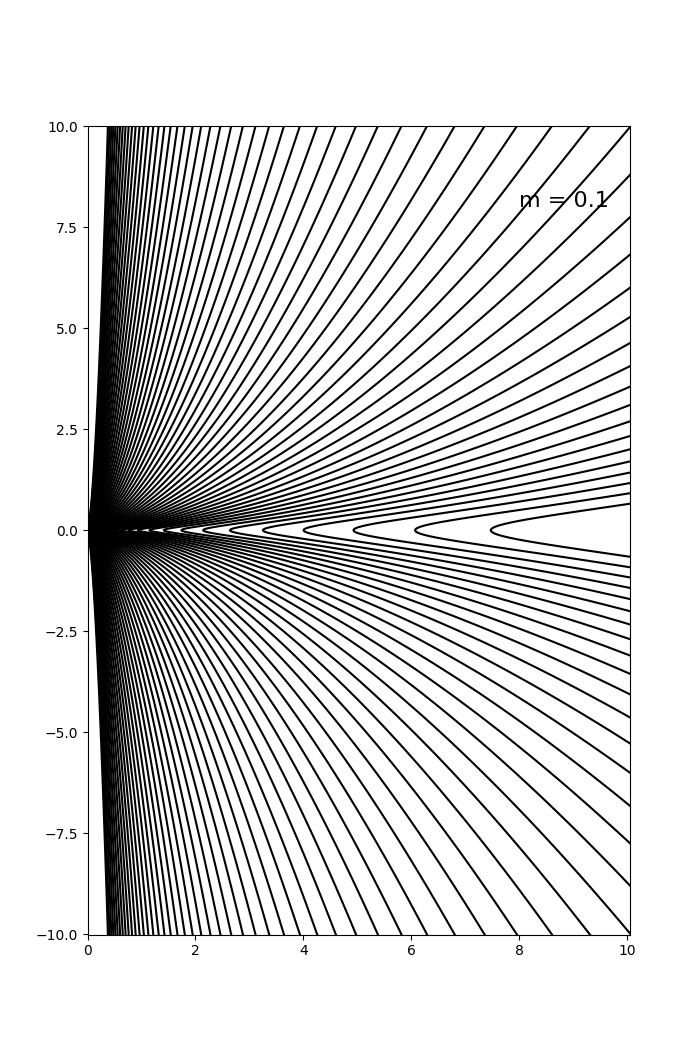

<IPython.core.display.Javascript object>


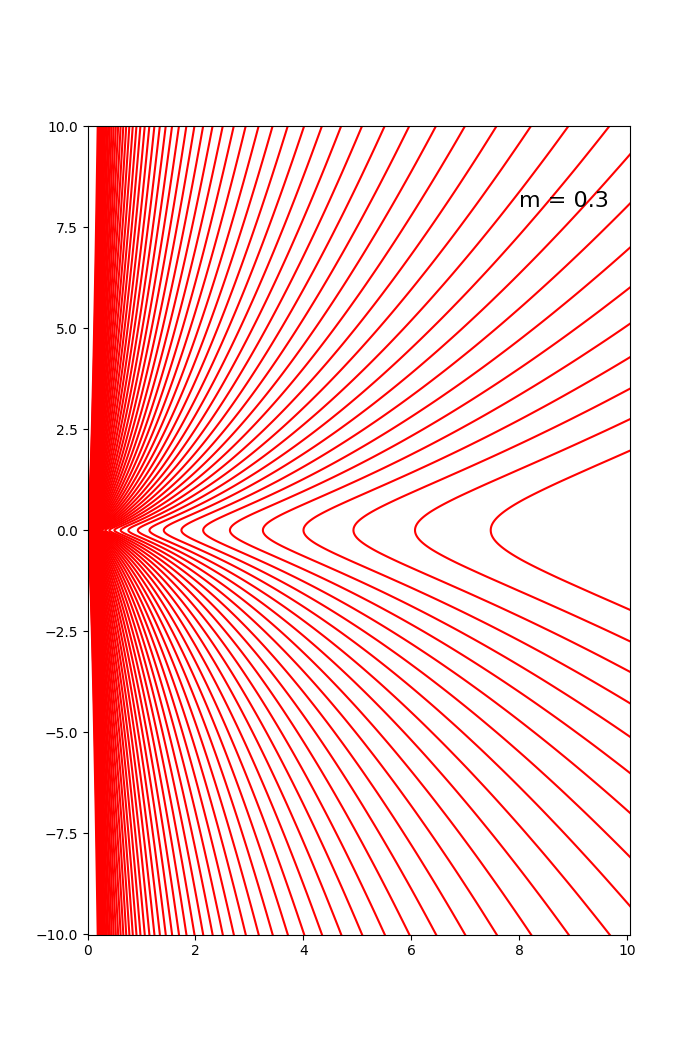

<IPython.core.display.Javascript object>


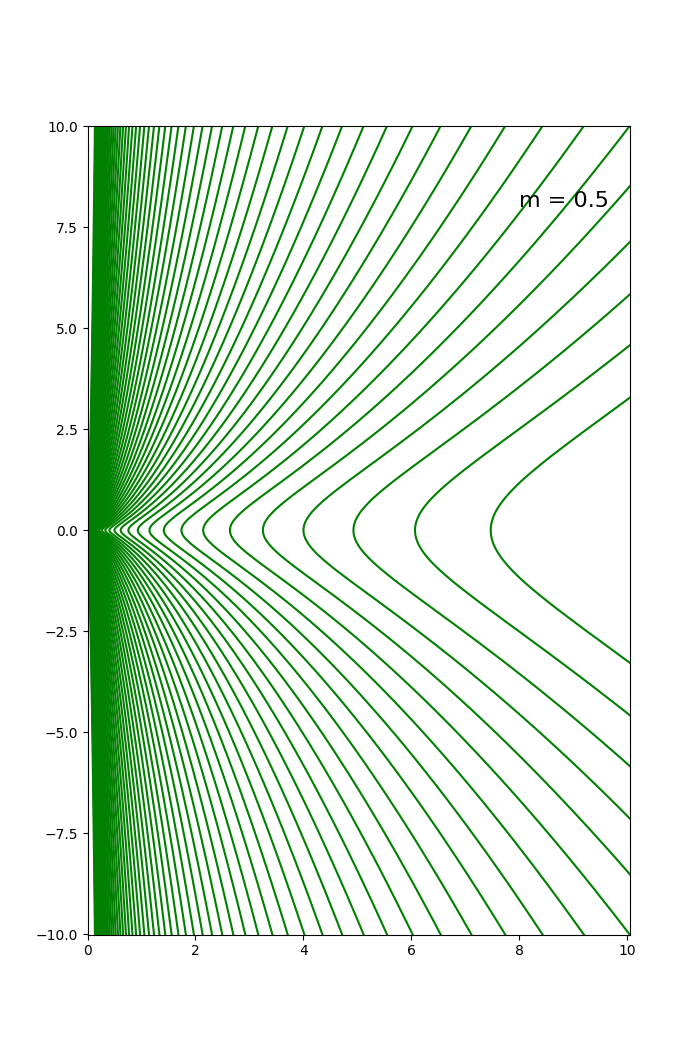

<IPython.core.display.Javascript object>


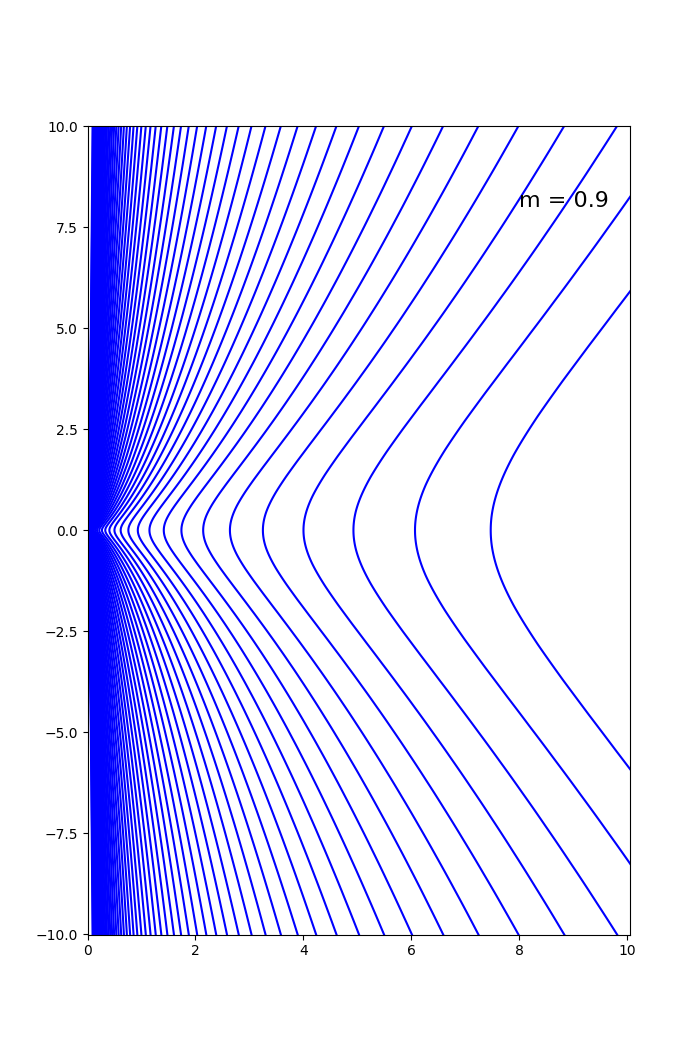

<IPython.core.display.Javascript object>


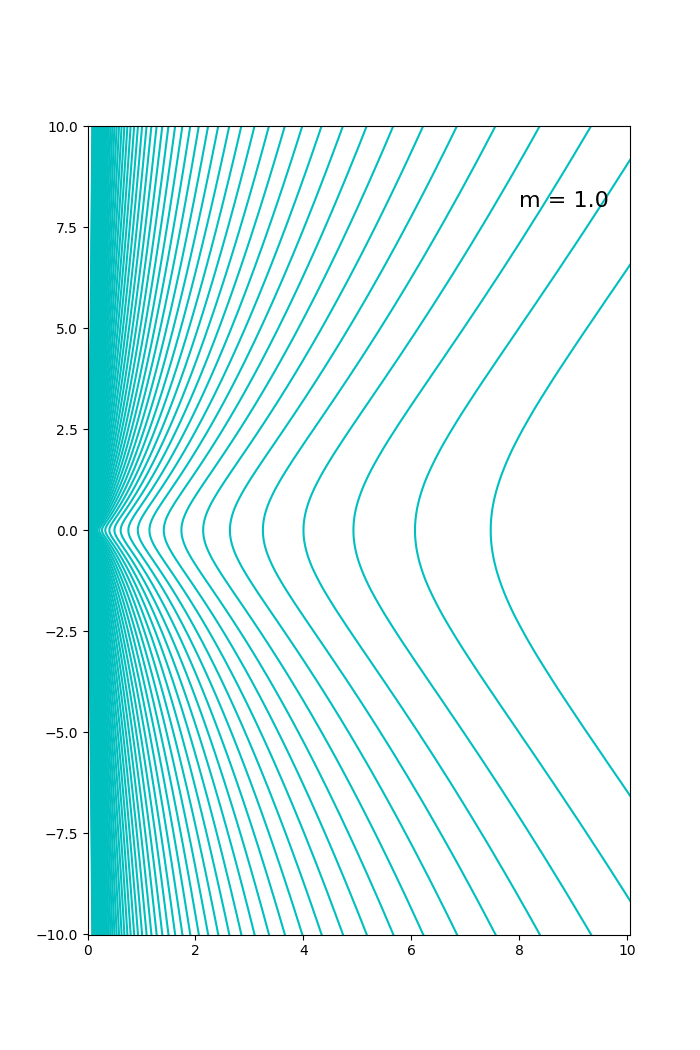

<IPython.core.display.Javascript object>


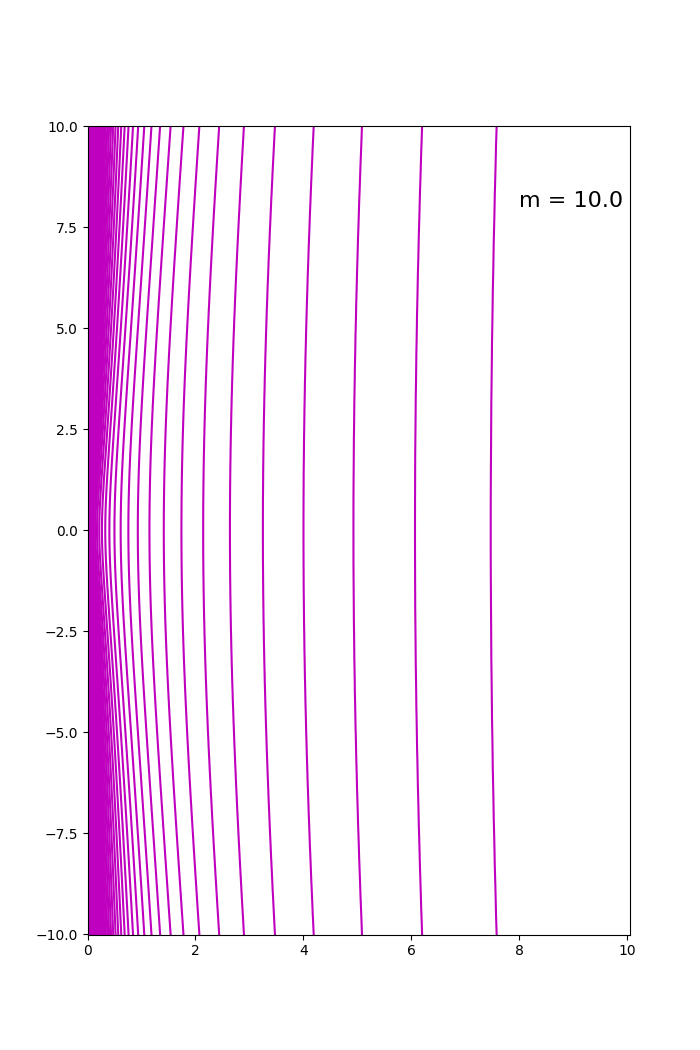

In [126]:
xx = rr * np.sin(tt)
zz = -rr * np.cos(tt)
import itertools
colrs = itertools.cycle(['k','r','g','b','c','m'])
levels = np.logspace(-3.0,1.0,60)
for psi,mm in zip(psis,m):
    figx = plt.figure(figsize=(7.0,10.5))
    figx.clf()
    cax = figx.add_subplot(1,1,1)
    cax.axis(xmin=0.0,xmax=10.05,ymin=-10.01,ymax=10.01)
    conf = plt.contour(xx,zz,psi,levels,colors=colrs.next(),extend='both',zorder=0.0)
    cax.annotate(xy=(8.0,8.0),s='m = '+str(mm),fontsize=16)

<IPython.core.display.Javascript object>


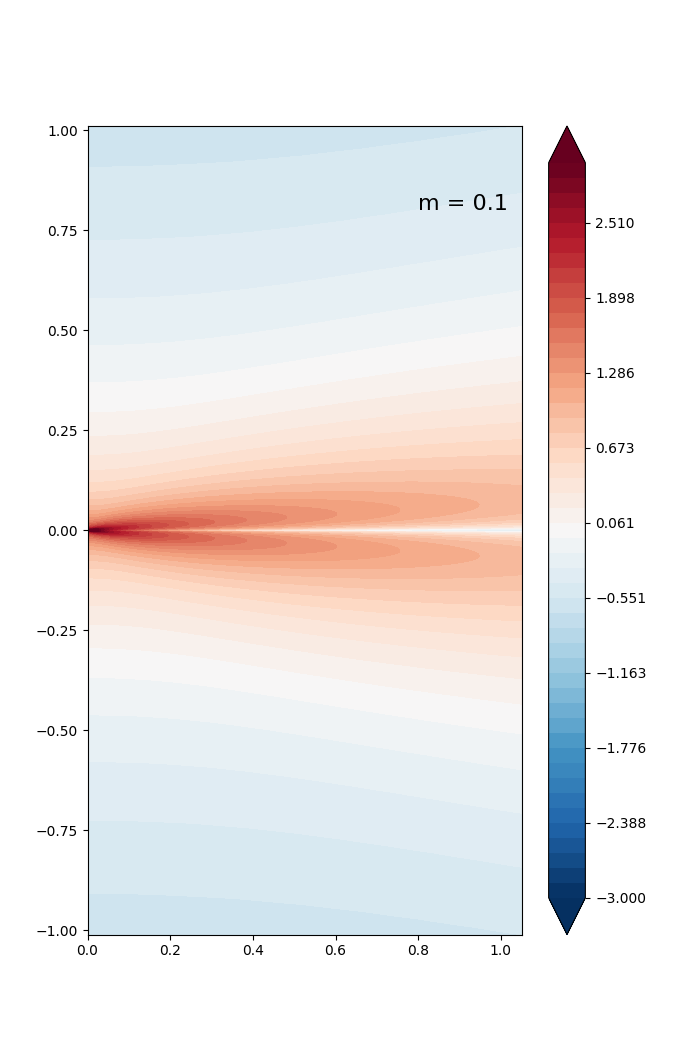

<IPython.core.display.Javascript object>


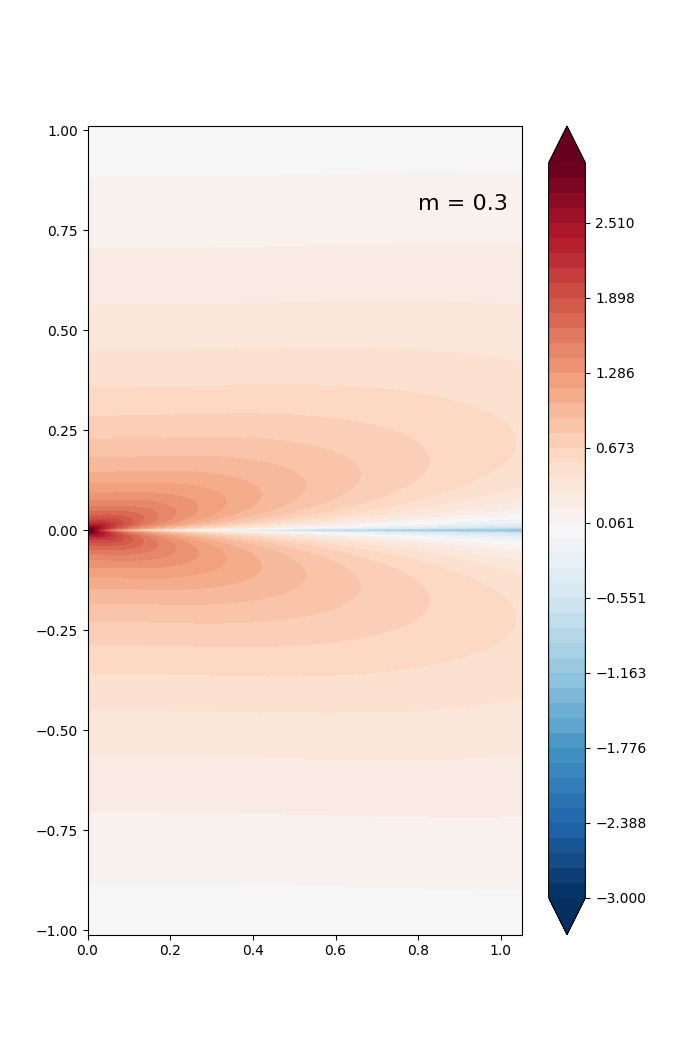

<IPython.core.display.Javascript object>


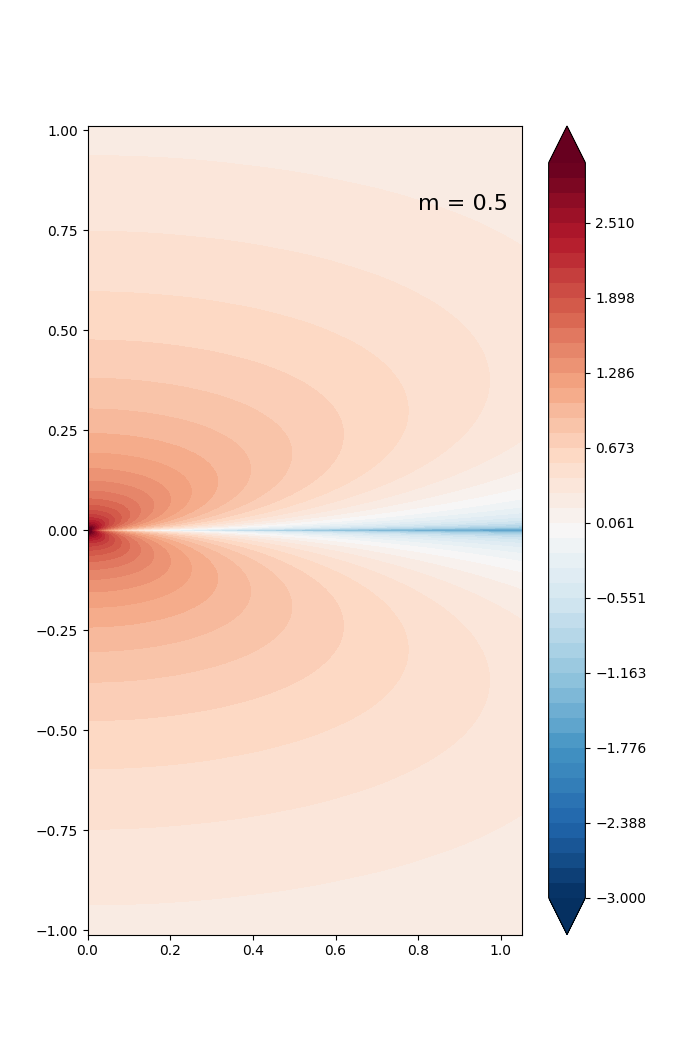

<IPython.core.display.Javascript object>


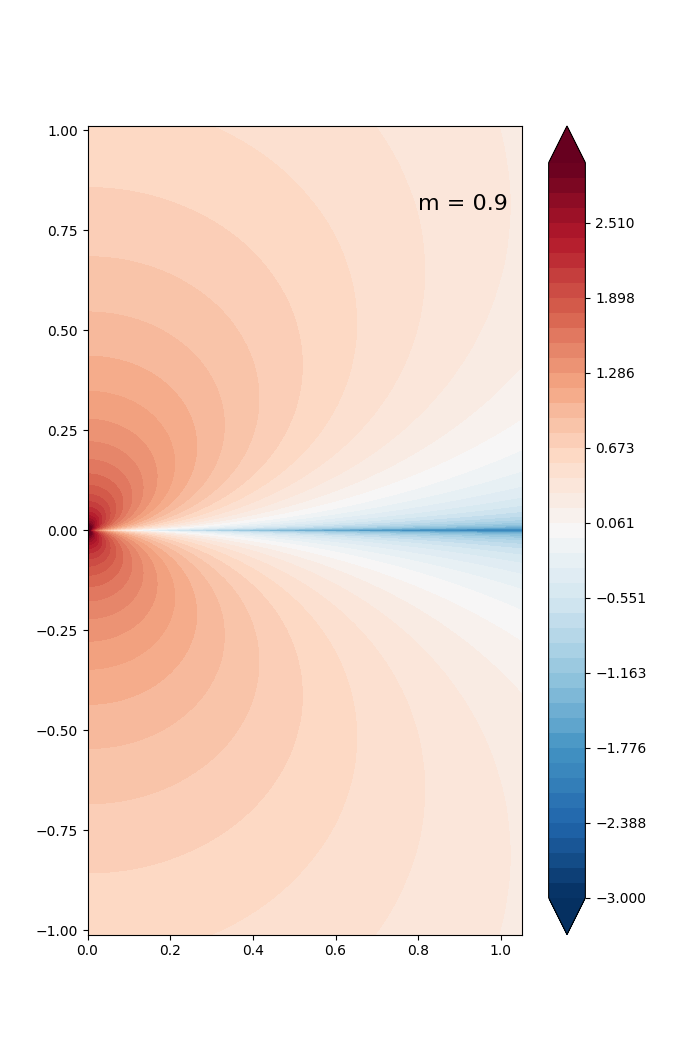

<IPython.core.display.Javascript object>


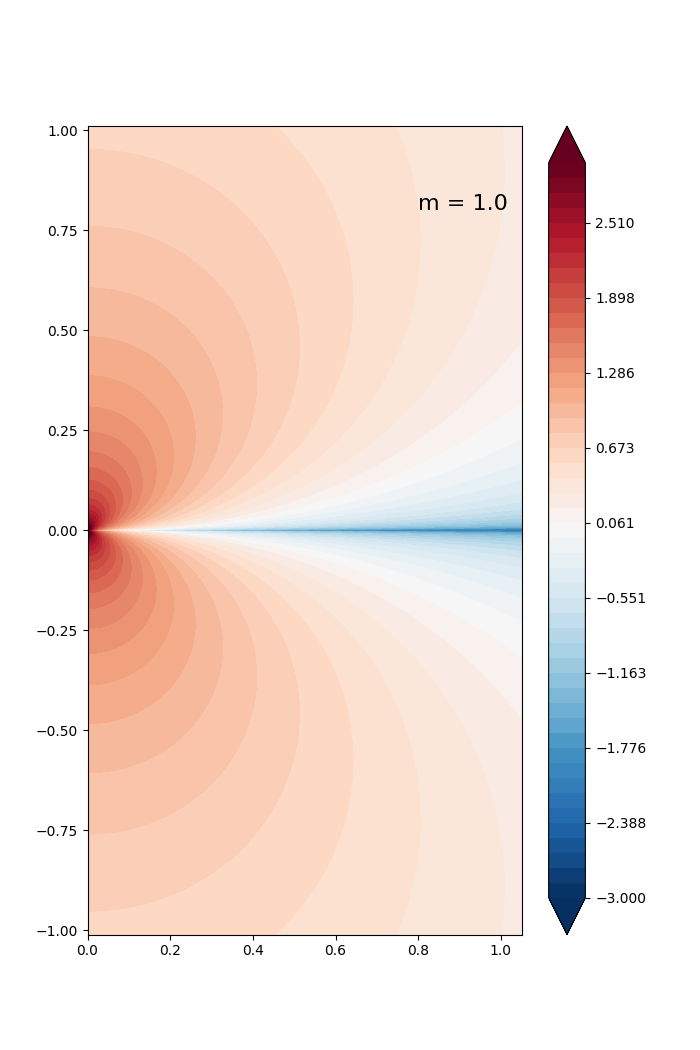

<IPython.core.display.Javascript object>


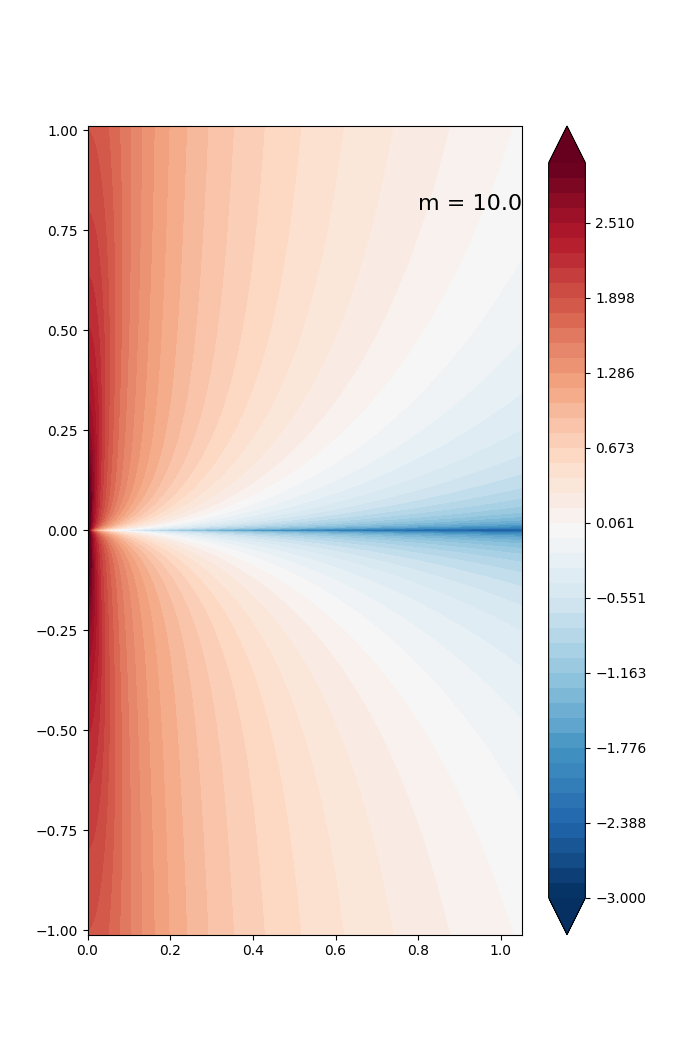

In [127]:
xx = rr * np.sin(tt)
zz = -rr * np.cos(tt)
import itertools
colrs = itertools.cycle(['k','r','g','b','c','m'])
levels = np.linspace(-3.0,3.0,50)
#levels = np.append(-1.0 * levels[::-1], levels)
for br,mm in zip(brs,m):
    figx = plt.figure(figsize=(7.0,10.5))
    figx.clf()
    cax = figx.add_subplot(1,1,1)
    cax.axis(xmin=0.0,xmax=1.05,ymin=-1.01,ymax=1.01)
    conf = plt.contourf(xx,zz,np.log10(np.abs(br)),levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    cax.annotate(xy=(0.8,0.8),s='m = '+str(mm),fontsize=16)
    plt.colorbar()

<IPython.core.display.Javascript object>


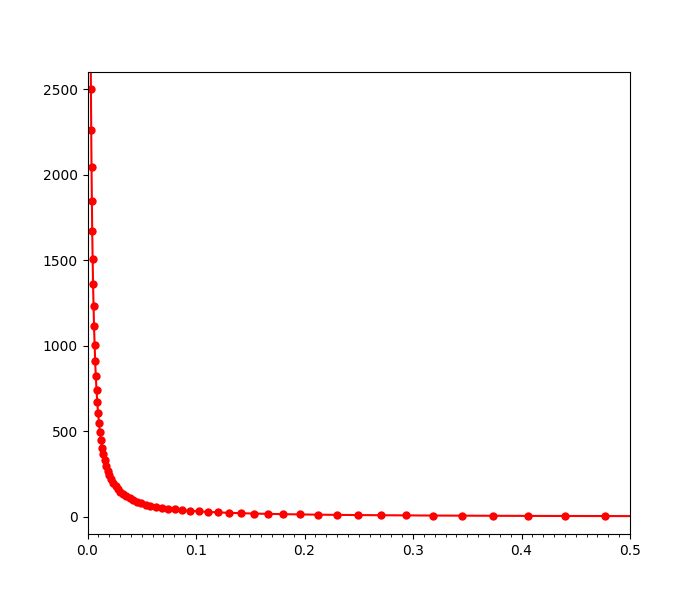

(200,) (200, 720)


In [159]:
from matplotlib.ticker import AutoMinorLocator
fig1d = plt.figure(figsize=(7.0,6.0))
fig1d.clf()
cax = fig1d.add_subplot(1,1,1)
cax.axis(xmax=0.5,ymax=2.6e3,ymin=-1e2)
br = brs[2]
print r.shape,br.shape
cax.plot(np.array(r),br[:,10],'ro-',mew=0.0)
cax.xaxis.set_minor_locator(AutoMinorLocator(10))

In [167]:
psi = psis[2]
print psi[93:95,10]
print psi[94,8:11]
print r[93:95]
print br[92:96,10]

[8.97868870e-05 9.54102039e-05]
[6.10568465e-05 7.72784683e-05 9.54102039e-05]
[0.01867914 0.02025502]
[298.47483195 269.73535045 243.76313007 220.29171735]
